<a href="https://colab.research.google.com/github/Ijlal40/Ijlal40.github.io/blob/master/LSTM_HandwritingRecognition_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###IMPORTANT
I would heavily recommend to swap the runtime to the T4 GPU available for free on Colab, running this via the CPU would take quite a bit of  (roughly a minute and 40 seconds per epoch) due to the dataset being optimized is rather large.

In [ ]:
#installing emnist database
!pip install emnist
from emnist import extract_training_samples, extract_test_samples

from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import matplotlib.pyplot as plt

from keras.utils import to_categorical
from keras.models import Sequential, Model

# fix random seed for reproducibility
seed = 7
np.random.seed(seed)

letters_labels = ['blank', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

X_train, y_train = extract_training_samples('letters')
X_test, y_test = extract_test_samples('letters')

X_train = X_train / 255.0 #Normalizing the data
X_test = X_test / 255.0

y_train = to_categorical(y_train) #One-hot encoding
y_test = to_categorical(y_test)

print("Train image shape ", X_train.shape)
print("Test image shape ", X_test.shape)

Train image shape  (124800, 28, 28)
Test image shape  (20800, 28, 28)


In [ ]:
model = keras.Sequential()
model.add(layers.LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
model.add(layers.LSTM(64))
model.add(layers.Dense(27, activation='softmax'))
print(model.summary())

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_4 (LSTM)               (None, 28, 64)            23808     
                                                                 
 lstm_5 (LSTM)               (None, 64)                33024     
                                                                 
 dense_2 (Dense)             (None, 27)                1755      
                                                                 
Total params: 58587 (228.86 KB)
Trainable params: 58587 (228.86 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


In [ ]:
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [ ]:
model.fit(X_train, y_train, validation_split=0.2, batch_size=256, epochs=20)
#Final evaluation of model
score = model.evaluate(X_test, y_test, verbose=0)
print("Tuned NN Error: %.2f%%" % (100-score[1]*100))

Epoch 1/20
390/390 [==============================] - 12s 19ms/step - loss: 1.3617 - accuracy: 0.6098 - val_loss: 0.6577 - val_accuracy: 0.8041
Epoch 2/20
390/390 [==============================] - 7s 17ms/step - loss: 0.5313 - accuracy: 0.8371 - val_loss: 0.4677 - val_accuracy: 0.8560
Epoch 3/20
390/390 [==============================] - 6s 15ms/step - loss: 0.3973 - accuracy: 0.8744 - val_loss: 0.3708 - val_accuracy: 0.8832
Epoch 4/20
390/390 [==============================] - 3s 9ms/step - loss: 0.3358 - accuracy: 0.8930 - val_loss: 0.3458 - val_accuracy: 0.8899
Epoch 5/20
390/390 [==============================] - 3s 9ms/step - loss: 0.2980 - accuracy: 0.9038 - val_loss: 0.3126 - val_accuracy: 0.8950
Epoch 6/20
390/390 [==============================] - 4s 11ms/step - loss: 0.2705 - accuracy: 0.9116 - val_loss: 0.2999 - val_accuracy: 0.9032
Epoch 7/20
390/390 [==============================] - 3s 8ms/step - loss: 0.2498 - accuracy: 0.9176 - val_loss: 0.2820 - val_accuracy: 0.9083
E

1/1 [==============================] - 0s 22ms/step

Predicted value: h
Actual value: h


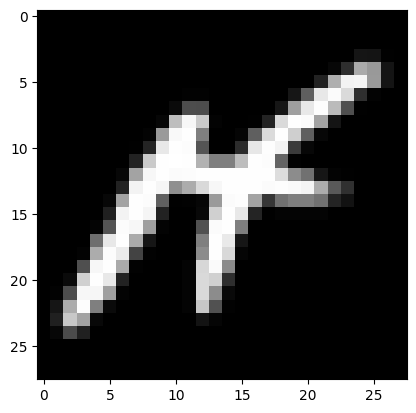

1/1 [==============================] - 0s 19ms/step

Predicted value: b
Actual value: b


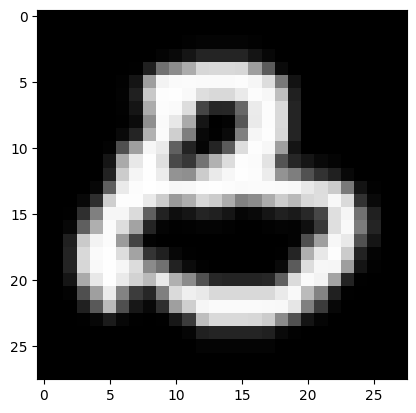

1/1 [==============================] - 0s 21ms/step

Predicted value: w
Actual value: w


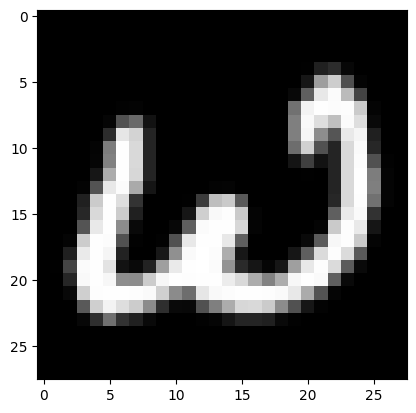

1/1 [==============================] - 0s 18ms/step

Predicted value: q
Actual value: q


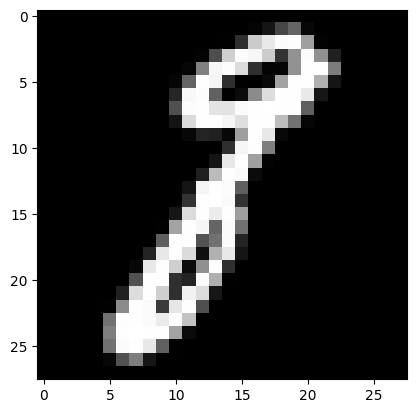

1/1 [==============================] - 0s 22ms/step

Predicted value: j
Actual value: j


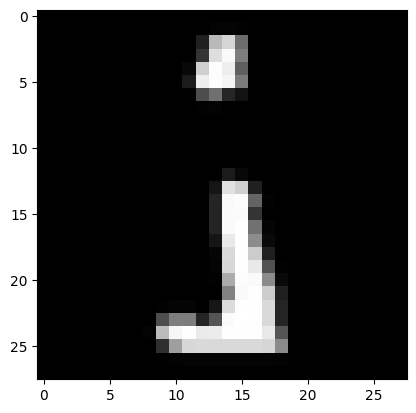

1/1 [==============================] - 0s 20ms/step

Predicted value: e
Actual value: e


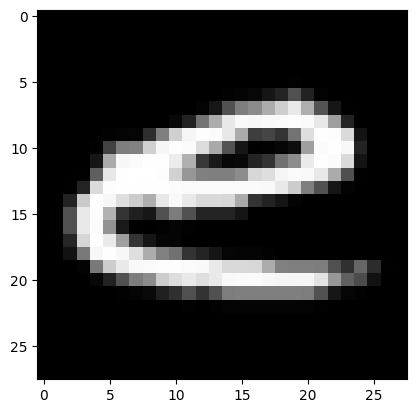

1/1 [==============================] - 0s 19ms/step

Predicted value: o
Actual value: o


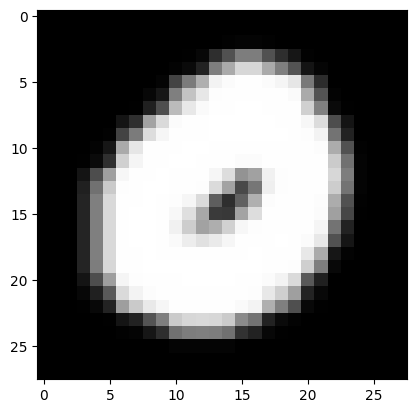

1/1 [==============================] - 0s 18ms/step

Predicted value: e
Actual value: e


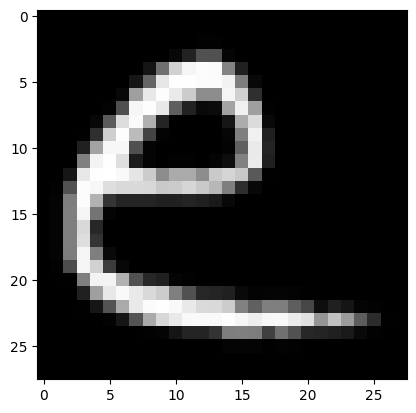

1/1 [==============================] - 0s 23ms/step

Predicted value: b
Actual value: b


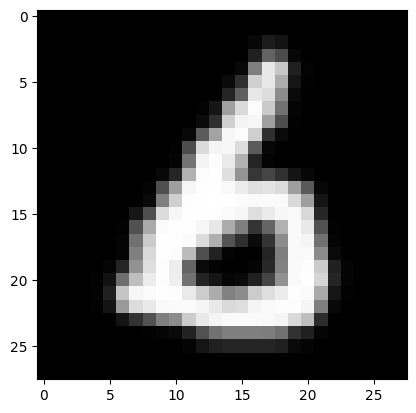

1/1 [==============================] - 0s 22ms/step

Predicted value: p
Actual value: p


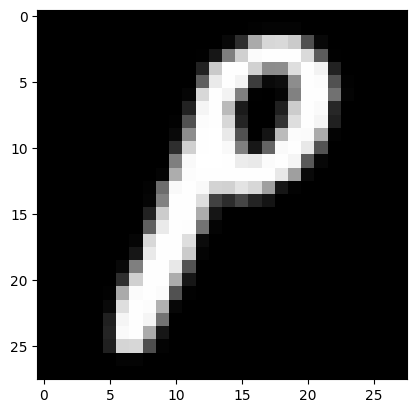

In [ ]:
for i in range(0,10):
  sample_num = np.random.randint(0, 20800)
  sample_img = X_test[sample_num].reshape(28,28)
  predicted_val = np.argmax(model.predict(X_test[sample_num][None]))
  actual_val = np.argmax(y_test[sample_num])
  print("\nPredicted value: " + str(letters_labels[predicted_val]))
  print("Actual value: " + str(letters_labels[actual_val]))
  plt.imshow(sample_img, cmap='gray')
  plt.show()